Componenents:

Causal Multi-Head Self-Attention

Feed-Forward Network (FFN)

Layer Normalization

Residual or Skip connections


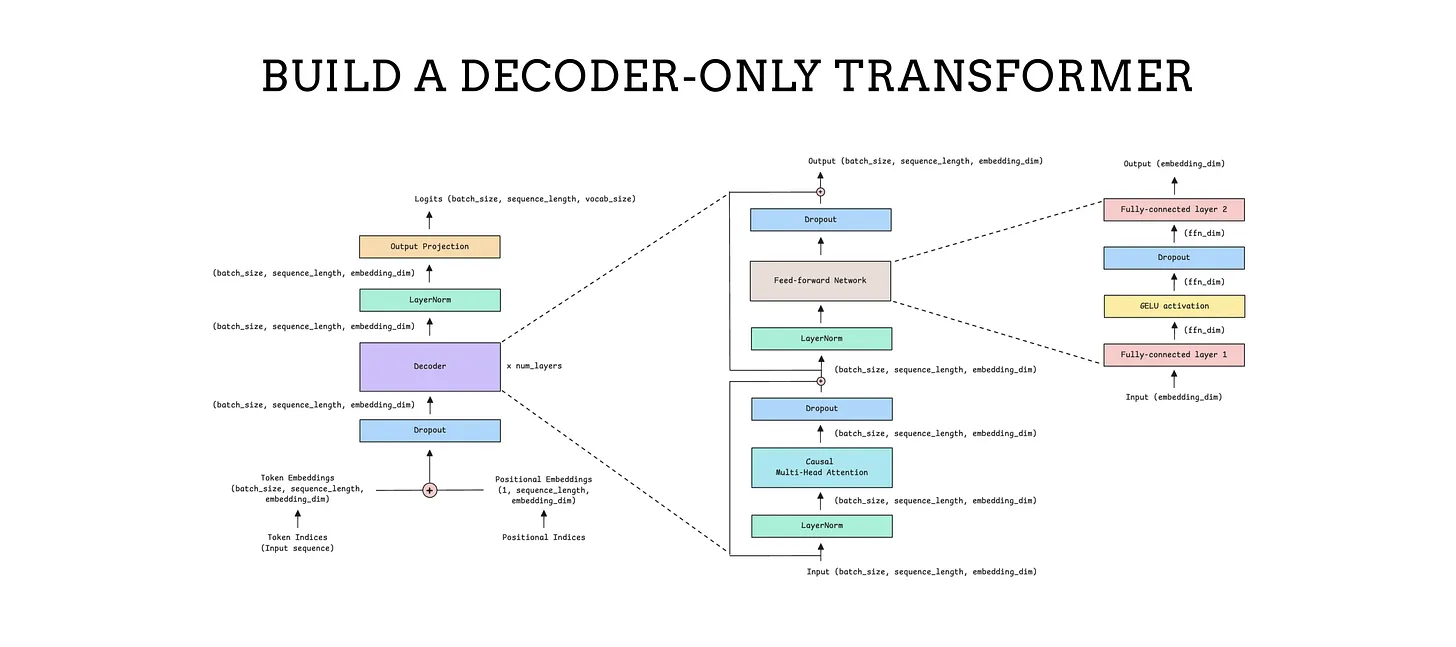

https://www.intoai.pub/p/build-a-decoder-only-transformer

TRANSFORMER MODEL

INPUTS = TOKEN IDX, POSITION IDX 

1. EMBEDDING OF BOTH

2. DROPOUT LAYER ???

3. DECODER layer
        - LAYERNORM
        - ATTENTION
        - DROPOUT

         FFN
        - LAYERNORM
        - FFN:
                -ffn1
                -relu?
                -dropout
                -ffn2
        - DROPOUT

layernorm

output projection

logits

# Data info

In [1]:
# Constants for the dataset and model
FAMILIES = ("AcyP", "HPr", "HU")
AA = "ACDEFGHIKLMNPQRSTVWY"
special_tokens = ["<PAD>", "<BOS>", "<EOS>"]
total_tokens = list(special_tokens) + list(AA)
IGNORE_INDEX = -1  # what F.cross_entropy(ignore_index=...) must be given for the generative task

In [ ]:
from protgen.data import ProteinDataset
from torch.utils.data import DataLoader

train_data = ProteinDataset(path_to_data="../data/train.csv")
val_data = ProteinDataset(path_to_data="../data/val.csv")
test_data = ProteinDataset(path_to_data="../data/test.csv")

print(f"Data class: {train_data}")

# Get tensors
X_train = train_data.tokens
y_train_labels = train_data.labels          # classification task
y_train_shifted = train_data.tokens_shifted # generative task

print(f"# Train data: \n Tokens shape: {X_train.shape}\n Labels (shape): {y_train_labels.shape} \n Shifted shape: {y_train_shifted.shape}")


# Indexing
x, x_shifted, y, length = train_data[0]
print(f"# Sample 0: \nTokens: \n {x}\n Shifted: \n {x_shifted}\n Label: {y}\n Length: {length}")

# DataLoader
train_loader = DataLoader(train_data, batch_size=32, shuffle=True)

Data class: ProteinDataset(num_samples=16020, vocab_size=23, num_classes=3, max_length=129)
# Train data: 
 Tokens shape: torch.Size([16020, 129])
 Labels (shape): torch.Size([16020]) 
 Shifted shape: torch.Size([16020, 129])
# Sample 0: 
Tokens: 
 tensor([ 1, 13, 10, 11, 11, 16,  7, 14, 10, 10, 11, 14, 19,  8,  7,  3, 17, 15,
         3, 19, 12, 12, 20, 11, 12, 18, 16, 17,  7, 19, 18,  5, 10, 18, 12,  6,
        22, 16,  8, 11, 19, 10, 14, 12, 11,  9, 18,  3, 11, 18, 10, 13,  5, 10,
        13, 18, 12, 18, 10, 17, 15,  8, 19, 11,  7, 22, 10, 11,  3,  6,  8, 10,
         5,  6, 20, 16,  3, 10, 16, 12, 10, 16,  5, 22, 12, 22, 11,  6, 11, 12,
        10, 14, 22,  2,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,
         0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,
         0,  0,  0])
 Shifted: 
 tensor([13, 10, 11, 11, 16,  7, 14, 10, 10, 11, 14, 19,  8,  7,  3, 17, 15,  3,
        19, 12, 12, 20, 11, 12, 18, 16, 17,  7, 19, 18,  5, 10, 18, 12,  6, 22

In [3]:
import torch
import pandas as pd
from torch.utils.data import Dataset, DataLoader
import torch.nn.functional as F
import torch.nn as nn

# test data
# input: 2 samples, sequence of tokens
example_protein_seq_data = torch.stack([train_data[0][0], train_data[1][0]])

y = torch.stack([train_data[0][1], train_data[1][1]])

example_protein_seq_data


tensor([[ 1, 13, 10, 11, 11, 16,  7, 14, 10, 10, 11, 14, 19,  8,  7,  3, 17, 15,
          3, 19, 12, 12, 20, 11, 12, 18, 16, 17,  7, 19, 18,  5, 10, 18, 12,  6,
         22, 16,  8, 11, 19, 10, 14, 12, 11,  9, 18,  3, 11, 18, 10, 13,  5, 10,
         13, 18, 12, 18, 10, 17, 15,  8, 19, 11,  7, 22, 10, 11,  3,  6,  8, 10,
          5,  6, 20, 16,  3, 10, 16, 12, 10, 16,  5, 22, 12, 22, 11,  6, 11, 12,
         10, 14, 22,  2,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,
          0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,
          0,  0,  0],
        [ 1, 13, 14, 11,  9,  6, 12, 10, 19, 17, 10, 18,  6, 11, 18,  8, 13, 19,
         11, 11,  5, 20,  6, 18, 20, 12, 14,  8,  7, 13,  5,  6, 20, 19,  5,  3,
         12,  8, 18,  8, 14, 11, 20, 16, 12, 10,  8,  7,  8, 19,  7,  6, 19, 17,
         11, 17, 18, 16, 17, 14,  8, 17, 14, 15, 16, 19,  8,  5, 19, 10, 19, 10,
         15,  3, 18, 19, 10, 15,  3,  7, 11,  3,  8, 18, 17, 12, 11,  8,  3, 20,
      

In [4]:
# TRUE output: shifted
# ignore_index = -1 (for loss function)
y

tensor([[13, 10, 11, 11, 16,  7, 14, 10, 10, 11, 14, 19,  8,  7,  3, 17, 15,  3,
         19, 12, 12, 20, 11, 12, 18, 16, 17,  7, 19, 18,  5, 10, 18, 12,  6, 22,
         16,  8, 11, 19, 10, 14, 12, 11,  9, 18,  3, 11, 18, 10, 13,  5, 10, 13,
         18, 12, 18, 10, 17, 15,  8, 19, 11,  7, 22, 10, 11,  3,  6,  8, 10,  5,
          6, 20, 16,  3, 10, 16, 12, 10, 16,  5, 22, 12, 22, 11,  6, 11, 12, 10,
         14, 22,  2, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1,
         -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1, -1,
         -1, -1, -1],
        [13, 14, 11,  9,  6, 12, 10, 19, 17, 10, 18,  6, 11, 18,  8, 13, 19, 11,
         11,  5, 20,  6, 18, 20, 12, 14,  8,  7, 13,  5,  6, 20, 19,  5,  3, 12,
          8, 18,  8, 14, 11, 20, 16, 12, 10,  8,  7,  8, 19,  7,  6, 19, 17, 11,
         17, 18, 16, 17, 14,  8, 17, 14, 15, 16, 19,  8,  5, 19, 10, 19, 10, 15,
          3, 18, 19, 10, 15,  3,  7, 11,  3,  8, 18, 17, 12, 11,  8,  3, 20, 11,
      

In [5]:
example_protein_seq_data.shape, y.shape

(torch.Size([2, 129]), torch.Size([2, 129]))

In [6]:
train_data.vocab, train_data.vocab_size

({'<PAD>': 0,
  '<BOS>': 1,
  '<EOS>': 2,
  'A': 3,
  'C': 4,
  'D': 5,
  'E': 6,
  'F': 7,
  'G': 8,
  'H': 9,
  'I': 10,
  'K': 11,
  'L': 12,
  'M': 13,
  'N': 14,
  'P': 15,
  'Q': 16,
  'R': 17,
  'S': 18,
  'T': 19,
  'V': 20,
  'W': 21,
  'Y': 22},
 23)

Starting with causal multi-head self attention

adapted from https://docs.pytorch.org/tutorials/intermediate/scaled_dot_product_attention_tutorial.html#causal-self-attention

# attention

In [7]:
import torch
import torch.nn as nn
import torch.nn.functional as F

device = "cuda" if torch.cuda.is_available() else "cpu"

batch_size = 2 # for now 
seq_len = 129 

embed_dim = 128 # this is 128 / 4 = 32 per head, altogether almost as seq_len (positional qualities per residue??)

"""
This name is a bit weird I coudn't undestand to what embed_dim relate but I am not that proficient on this subject as well.
"""

num_heads= 4
pad_idx= train_data.vocab["<PAD>"] # 0 


# i need to combine causal and padding mask
# causal mask = -inf for upper right triangle
# padding mask = -inf for all padding tokens (0) 

"""
 got it padding but why do we do it in the padding?
"""

# attn_mask (true, false) -> the ones that are false are not being part of attention


# need to put the upper left triangle that is still true to false in the attn mask to make it causal as well


# hooooowwwwww ???????????

# Q, K, V shapes: (batch_size, num_heads, seq_len, head_dim) 
# attention scores shape: (batch_size, num_heads, seq_len, seq_len)
# mask shape: (batch_size, 1 (broadcasts to num_heads), seq_len, seq_len)

# causal mask is just diagional upper right triangle False, lower left and diagonal True
# padding mask i need to look for padding tokens in input sequence (when the sequence is done before max length)

# adapted from https://docs.pytorch.org/tutorials/intermediate/scaled_dot_product_attention_tutorial.html#causal-self-attention
class CausalMultiHeadSelfAttention(nn.Module):

    # doesn't have is_causal because we also have padding so need to combine causal + padding mask 
    
    def __init__(self, num_heads: int, embed_dimension: int, bias: bool=False, dropout:float=0.0):

        """
        I would probably change the names of the dimensions 
        """
        
        super().__init__()
        # This is a cool assert
        # it is correct but we might want a different architecture no?
        assert embed_dimension % num_heads == 0
        
        # key, query, value projections for all heads, but in a batch

        # 128, 384
        # They're the token's q, k and v, side by side:
        # one token's output (384 numbers):
        # [ ─── q (128) ─── | ─── k (128) ─── | ─── v (128) ─── ]

        # q (128) = [ head1 (32) | head2 (32) | head3 (32) | head4 (32) ]

        self.c_attn = nn.Linear(embed_dimension, 3 * embed_dimension, bias=bias)
        
        # output projection
        self.c_proj = nn.Linear(embed_dimension, embed_dimension, bias=bias)
        
        # regularization
        self.dropout = dropout
        self.resid_dropout = nn.Dropout(dropout)
        self.num_heads = num_heads
        self.embed_dimension = embed_dimension
        self.pad_idx = pad_idx
        self.padding_mask = padding_mask
        self.causal_mask = causal_mask
        self.head_dim = embed_dimension // num_heads    

    def forward(self, x, attn_mask):
        
        # calculate query, key, values for all heads in batch and move head forward to be the batch dim
        query_projected = self.c_attn(x)

        batch_size = query_projected.size(0)
        seq_len = query_projected.size(1)
        

        # separate query, key, value and reshape for multi-head attention
        query, key, value = query_projected.chunk(3, -1)
        # reshape to (batch_size, num_heads, seq_len, head_dim)
        query = query.view(batch_size, -1, self.num_heads, self.head_dim).transpose(1, 2)
        key = key.view(batch_size, -1, self.num_heads, self.head_dim).transpose(1, 2)
        value = value.view(batch_size, -1, self.num_heads, self.head_dim).transpose(1, 2)

        # noww masks (moved to decoder because of embedding????)
        
        # https://docs.pytorch.org/docs/2.15/generated/torch.tril.html
        # causal_mask = torch.tril(torch.ones(seq_len, seq_len)).unsqueeze(0).unsqueeze(1)  # shape is now (1, 1, seq_len, seq_len)
        # have to change it to boolean mask
        # causal_mask = causal_mask.bool()
        # shape of x is (batch_size, seq_len, embed_dim) 
        # boolean mask: shape of x -> remove last dim -> unsqueeze twice
        
        # inside the transformer this function gets embedded data so it doesnt work it's not tokens!!
        # have to move it to the transformer class and get the tokens from there and pass it to this function
        # padding_mask = (x != self.pad_idx).any(dim=-1).unsqueeze(1).unsqueeze(2)  # shape is now (batch_size, 1, 1, seq_len)
        
        
        # FINAL MASK
        # attn_mask = causal_mask & padding_mask  # shape is now (batch_size, 1, seq_len, seq_len)
        #print(causal_mask.shape, padding_mask.shape, attn_mask.shape)
        
        
        #print("Causal mask: ", causal_mask)
        #print("Padding mask: ", padding_mask)
        #print("Attention mask: ", attn_mask)        
        

        y = F.scaled_dot_product_attention(query, key, value, 
                                           attn_mask=attn_mask, 
                                           dropout_p=self.dropout, 
                                           is_causal=False)
        
        y = y.transpose(1, 2).reshape(batch_size, -1, self.num_heads * self.head_dim)

        y = self.resid_dropout(self.c_proj(y))
        return y

## Test Padding options

In [8]:
# TEST

short_example = example_protein_seq_data[:,:10].clone()  # take first 10 tokens of each sample  
short_example[0, 5:] = 0  # fake padding
short_example[1, 8:] = 0 
print(f"Short example shape: {short_example.shape}")
print(f"Short example: {short_example}")

embedding_layer = nn.Embedding(train_data.vocab_size, embed_dim, padding_idx=pad_idx)
padding_mask = (short_example != pad_idx).unsqueeze(1).unsqueeze(2)
causal_mask = torch.tril(torch.ones(short_example.size(1), short_example.size(1))).unsqueeze(0).unsqueeze(1).bool()

# I like the way this is done
attn_mask = causal_mask & padding_mask  # shape is now (batch_size, 1, seq_len, seq_len)

# PyTorch combines them with broadcasting: when two tensors have different shapes, any dimension of 
# size 1 gets copied (stretched) to match the other tensor's size.

x = embedding_layer(short_example)
csa = CausalMultiHeadSelfAttention(num_heads=num_heads, embed_dimension=embed_dim,  dropout=0.0)
output = csa.forward(x, attn_mask=attn_mask)
print(f"Output shape: {output.shape}")
print(f"Output: {output}")

# looks correct to me!!


Short example shape: torch.Size([2, 10])
Short example: tensor([[ 1, 13, 10, 11, 11,  0,  0,  0,  0,  0],
        [ 1, 13, 14, 11,  9,  6, 12, 10,  0,  0]])
Output shape: torch.Size([2, 10, 128])
Output: tensor([[[ 0.1990, -0.2923,  0.2915,  ...,  0.6418,  0.0957, -0.2620],
         [-0.0733, -0.0779,  0.2026,  ...,  0.2253,  0.2421, -0.2481],
         [-0.3261,  0.0797,  0.2164,  ...,  0.3269,  0.2907, -0.2469],
         ...,
         [ 0.0521,  0.1320,  0.2793,  ...,  0.2776,  0.1242, -0.1517],
         [ 0.0521,  0.1320,  0.2793,  ...,  0.2776,  0.1242, -0.1517],
         [ 0.0521,  0.1320,  0.2793,  ...,  0.2776,  0.1242, -0.1517]],

        [[ 0.1990, -0.2923,  0.2915,  ...,  0.6418,  0.0957, -0.2620],
         [-0.0733, -0.0779,  0.2026,  ...,  0.2253,  0.2421, -0.2481],
         [-0.3005, -0.0388,  0.1937,  ..., -0.0956,  0.1492, -0.1890],
         ...,
         [-0.1977,  0.0929,  0.0663,  ...,  0.0418, -0.0062, -0.1349],
         [-0.1697,  0.0960,  0.0577,  ...,  0.0158,  0.0

In [9]:
padding_mask = (short_example != pad_idx)
print(padding_mask.shape)
padding_mask

torch.Size([2, 10])


tensor([[ True,  True,  True,  True,  True, False, False, False, False, False],
        [ True,  True,  True,  True,  True,  True,  True,  True, False, False]])

In [10]:
padding_mask = (short_example != pad_idx).unsqueeze(1).unsqueeze(2)
print(padding_mask.shape)
padding_mask

torch.Size([2, 1, 1, 10])


tensor([[[[ True,  True,  True,  True,  True, False, False, False, False, False]]],


        [[[ True,  True,  True,  True,  True,  True,  True,  True, False, False]]]])

In [11]:
causal_mask = torch.tril(torch.ones(short_example.size(1), short_example.size(1)))
print(causal_mask.shape)
causal_mask

# so upper triangle does the job in here torch.tril

torch.Size([10, 10])


tensor([[1., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
        [1., 1., 0., 0., 0., 0., 0., 0., 0., 0.],
        [1., 1., 1., 0., 0., 0., 0., 0., 0., 0.],
        [1., 1., 1., 1., 0., 0., 0., 0., 0., 0.],
        [1., 1., 1., 1., 1., 0., 0., 0., 0., 0.],
        [1., 1., 1., 1., 1., 1., 0., 0., 0., 0.],
        [1., 1., 1., 1., 1., 1., 1., 0., 0., 0.],
        [1., 1., 1., 1., 1., 1., 1., 1., 0., 0.],
        [1., 1., 1., 1., 1., 1., 1., 1., 1., 0.],
        [1., 1., 1., 1., 1., 1., 1., 1., 1., 1.]])

In [12]:
causal_mask = torch.tril(torch.ones(short_example.size(1), short_example.size(1))).unsqueeze(0).unsqueeze(1).bool()
print(causal_mask.shape)
causal_mask

torch.Size([1, 1, 10, 10])


tensor([[[[ True, False, False, False, False, False, False, False, False, False],
          [ True,  True, False, False, False, False, False, False, False, False],
          [ True,  True,  True, False, False, False, False, False, False, False],
          [ True,  True,  True,  True, False, False, False, False, False, False],
          [ True,  True,  True,  True,  True, False, False, False, False, False],
          [ True,  True,  True,  True,  True,  True, False, False, False, False],
          [ True,  True,  True,  True,  True,  True,  True, False, False, False],
          [ True,  True,  True,  True,  True,  True,  True,  True, False, False],
          [ True,  True,  True,  True,  True,  True,  True,  True,  True, False],
          [ True,  True,  True,  True,  True,  True,  True,  True,  True,  True]]]])

In [13]:
attn_mask = causal_mask & padding_mask 

attn_mask

tensor([[[[ True, False, False, False, False, False, False, False, False, False],
          [ True,  True, False, False, False, False, False, False, False, False],
          [ True,  True,  True, False, False, False, False, False, False, False],
          [ True,  True,  True,  True, False, False, False, False, False, False],
          [ True,  True,  True,  True,  True, False, False, False, False, False],
          [ True,  True,  True,  True,  True, False, False, False, False, False],
          [ True,  True,  True,  True,  True, False, False, False, False, False],
          [ True,  True,  True,  True,  True, False, False, False, False, False],
          [ True,  True,  True,  True,  True, False, False, False, False, False],
          [ True,  True,  True,  True,  True, False, False, False, False, False]]],


        [[[ True, False, False, False, False, False, False, False, False, False],
          [ True,  True, False, False, False, False, False, False, False, False],
          [ 

# feed forward nn

Now what shape should it have ???

paper says FFNN with 2 linear transformations FFN(x) = max(0, xW1 + b1)W2 + b2 -> that is 2 layers

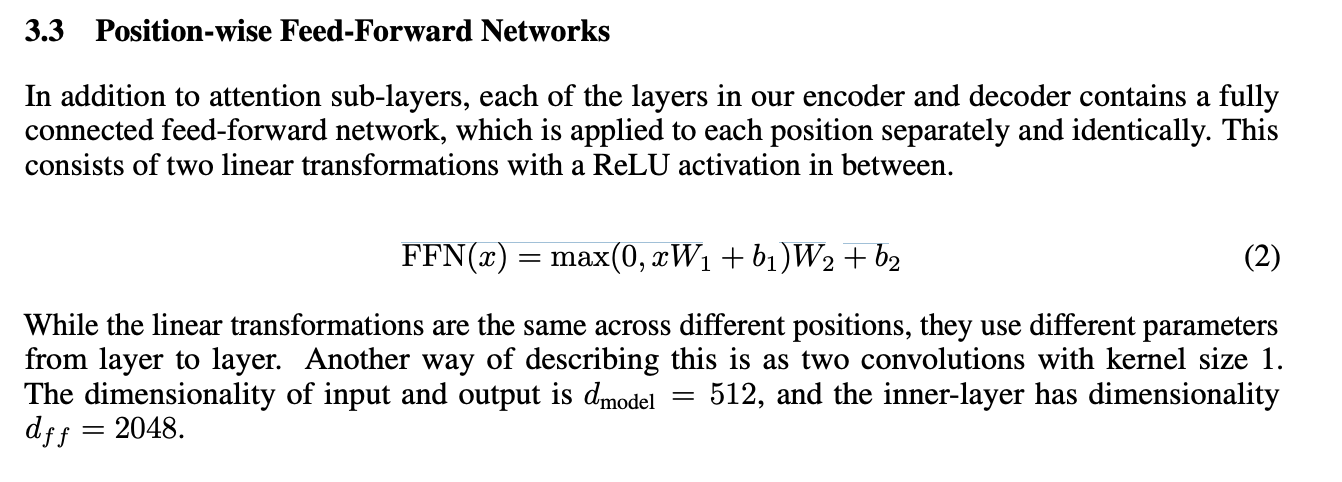

In [14]:
# adapted from https://www.geeksforgeeks.org/deep-learning/transformer-using-pytorch/ and https://www.intoai.pub/p/build-a-decoder-only-transformer

# from the paper: d_ff = 4 * d_model

class PositionWiseFeedForward(nn.Module):
    def __init__(self, d_model, d_ff, dropout=0.01):
        
        super().__init__()
        self.fc1 = nn.Linear(d_model, d_ff)
        self.gelu = nn.GELU() # used now more
        self.dropout = nn.Dropout(dropout)
        self.fc2 = nn.Linear(d_ff, d_model)

    def forward(self, x):
        x = self.fc1(x)
        x = self.gelu(x)
        x = self.dropout(x)
        x = self.fc2(x)
        return x

In [15]:
class DecoderLayer(nn.Module):
    
    # layernorm
    # attention
    # dropout 
    
    # layernorm
    # feedforward
    # dropout
    
    def __init__(self, embedding_dim: int, ff_dim: int, num_heads: int, dropout=0.1):
        
        super().__init__()
        
        # define things here

        self.attention = CausalMultiHeadSelfAttention(num_heads=num_heads, 
                                                      embed_dimension=embedding_dim,  
                                                      dropout=dropout)

        self.ffn = PositionWiseFeedForward(embedding_dim, ff_dim, dropout)

        # pre-LN
        # 2 because 2 sublayers: attention and feedforward
        # they have different parameters
        self.ln1 = nn.LayerNorm(embedding_dim)
        self.ln2 = nn.LayerNorm(embedding_dim)

        # dropout applied to sublayer outputs for regularization
        # for now 1 dropout for every time
        # we can change this later
        self.dropout = nn.Dropout(dropout)

    def forward(self, x, attn_mask):
        
        # here goes the structure
        
        # attention sublayer
        ln1_output = self.ln1(x)
        attention_output = self.attention(ln1_output, attn_mask)
        dropout_output = self.dropout(attention_output)
        x = x + dropout_output  # residual connection
        
        # ffnn sublayer
        ln2_output = self.ln2(x)
        ffn_output = self.ffn(ln2_output)
        dropout_ffn_output = self.dropout(ffn_output)
        x = x + dropout_ffn_output # residual connection

        return x

In [16]:
# code again adapted from the awesome https://www.intoai.pub/p/build-a-decoder-only-transformer

class DecoderOnlyTransformer(nn.Module):

    def __init__(self, vocab_size, embedding_dim, num_heads, ff_dim, 
                 num_layers, max_seq_length, pad_idx=0, dropout=0.1):

        """
        - self it's me man
        - vocab_size will be our vocabulary size
        - embeding_dim, I think it is straight forward as well what it is. What is the size of out embedings of each token
        - num_heads, this is just the number of heads in our transformer
        - ff_dim dimensions, feedforward middle dimension
        - num_layers, number of decoder layers.
        - max_seq_lenght - max lenght of the sequences
        """
        super().__init__()
        
        self.embedding_dim = embedding_dim
        self.max_seq_length = max_seq_length
        self.pad_idx = pad_idx # for the padding mask that has to be made before embedding

        
        # token embeddings
        self.token_embedding = nn.Embedding(vocab_size, embedding_dim)

        # positional embeddings
        self.positional_embedding = nn.Embedding(max_seq_length, 
        embedding_dim)

        # dropout
        self.dropout = nn.Dropout(dropout)

        # Stack of Decoder blocks (DecoderLayer)
        self.decoders = nn.ModuleList([
            DecoderLayer(embedding_dim, ff_dim, num_heads, dropout) for _ in range(num_layers)
        ])

        # FINAL layernorm before output
        self.final_ln = nn.LayerNorm(embedding_dim)

        # output projection to vocabulary
        self.output_proj = nn.Linear(embedding_dim, vocab_size)

    def forward(self, x, return_hidden_states=False):
        # x represents token indices
        batch_size, seq_length = x.shape
        # print(batch_size)
        # print(seq_length)
        
        # MASKS MOVED HERE BECAUSE THEY WANT TOKENS
        # padding mask for attention
        padding_mask = (x != self.pad_idx).unsqueeze(1).unsqueeze(2)

        print(f" shape of padding mask: {padding_mask.shape}")
        # causal mask for attention
        causal_mask = torch.tril(torch.ones(seq_length, seq_length, device= x.device)).unsqueeze(0).unsqueeze(1).bool()
        # combine masks

        print(f" shape of casual mask: {causal_mask.shape}")
        attn_mask = causal_mask & padding_mask  # shape is now (batch_size, 1, seq_len, seq_len)

        print(f" shape of the attention mask: {attn_mask.shape}")
        # print(attn_mask[0])
        

        # Create positional indices
        # Unsqueeze(0) adds a new dimension at position 0 allowing positional embeddings to be broadcast across the batch :)
        positions = torch.arange(0, seq_length, device = x.device).unsqueeze(0)
        print(f" position vector shape: {positions.shape}")

        # Create token embedding
        token_embedding = self.token_embedding(x)
        print(f"Token embedings shape:{token_embedding.shape} last position is embeding size")

        # Create positional embedding
        positional_embedding = self.positional_embedding(positions)
        print(f"Positional embedings shape:{positional_embedding.shape}")

        # Combine embeddings and add Dropout
        x = self.dropout(token_embedding + positional_embedding)
        print(f"Combining ntoken embeding and positional embeding with the dropout {x}")

        # Forward pass through decoder blocks
        for decoder in self.decoders:
          x = decoder(x, attn_mask=attn_mask)  # pass the attention mask to each decoder layer

        # Apply LayerNorm to the output
        x = self.final_ln(x)
        
        
        # ADDED THIS BECAUSE CLASSIFIER 
        # needs to see what model was thinking before logits
        if return_hidden_states:
            return x  

        # Output projection to vocabulary to get logits
        logits = self.output_proj(x) 

        return logits 

In [17]:
# TESTING THE FULL MODEL NOW !!!

embed_dim = 128
num_heads = 4
num_layers = 2
max_seq_length = 129
pad_idx = train_data.vocab["<PAD>"]  # 0


babys_first_transformer = DecoderOnlyTransformer(vocab_size=train_data.vocab_size,
                                                 embedding_dim=embed_dim,
                                                 num_heads=num_heads,
                                                 ff_dim=embed_dim*4,
                                                 num_layers=2,
                                                 max_seq_length=max_seq_length,
                                                 pad_idx=pad_idx,
                                                 dropout=0.1)


output_logits = babys_first_transformer(example_protein_seq_data)

 shape of padding mask: torch.Size([2, 1, 1, 129])
 shape of casual mask: torch.Size([1, 1, 129, 129])
 shape of the attention mask: torch.Size([2, 1, 129, 129])
 position vector shape: torch.Size([1, 129])
Token embedings shape:torch.Size([2, 129, 128]) last position is embeding size
Positional embedings shape:torch.Size([1, 129, 128])
Combining ntoken embeding and positional embeding with the dropout tensor([[[ 2.3664,  0.9401,  1.5966,  ..., -2.1134,  1.8957,  2.4113],
         [ 0.0000, -0.0953,  2.5655,  ..., -0.5959,  0.0000, -0.0143],
         [-0.3401, -0.0000,  1.7701,  ..., -0.9412, -1.9900,  1.6524],
         ...,
         [-3.4408,  0.0000, -0.3642,  ...,  1.9246,  0.6347, -1.1219],
         [-3.4211,  0.9300,  0.2786,  ..., -0.0000,  0.6051,  1.0243],
         [-3.5163,  2.2343,  0.8918,  ...,  0.8532,  0.6886,  0.7977]],

        [[ 2.3664,  0.9401,  1.5966,  ..., -2.1134,  1.8957,  2.4113],
         [ 0.1178, -0.0953,  2.5655,  ..., -0.5959,  1.8031, -0.0143],
         [

In [18]:
print(example_protein_seq_data)

output_logits = babys_first_transformer(example_protein_seq_data)
print(f"Output logits shape: {output_logits.shape}")
print(f"Output logits: {output_logits}")

tensor([[ 1, 13, 10, 11, 11, 16,  7, 14, 10, 10, 11, 14, 19,  8,  7,  3, 17, 15,
          3, 19, 12, 12, 20, 11, 12, 18, 16, 17,  7, 19, 18,  5, 10, 18, 12,  6,
         22, 16,  8, 11, 19, 10, 14, 12, 11,  9, 18,  3, 11, 18, 10, 13,  5, 10,
         13, 18, 12, 18, 10, 17, 15,  8, 19, 11,  7, 22, 10, 11,  3,  6,  8, 10,
          5,  6, 20, 16,  3, 10, 16, 12, 10, 16,  5, 22, 12, 22, 11,  6, 11, 12,
         10, 14, 22,  2,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,
          0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,  0,
          0,  0,  0],
        [ 1, 13, 14, 11,  9,  6, 12, 10, 19, 17, 10, 18,  6, 11, 18,  8, 13, 19,
         11, 11,  5, 20,  6, 18, 20, 12, 14,  8,  7, 13,  5,  6, 20, 19,  5,  3,
         12,  8, 18,  8, 14, 11, 20, 16, 12, 10,  8,  7,  8, 19,  7,  6, 19, 17,
         11, 17, 18, 16, 17, 14,  8, 17, 14, 15, 16, 19,  8,  5, 19, 10, 19, 10,
         15,  3, 18, 19, 10, 15,  3,  7, 11,  3,  8, 18, 17, 12, 11,  8,  3, 20,
      

In [19]:
padding_mask = (x != 0).any(dim=-1).unsqueeze(1).unsqueeze(2)
padding_mask.dtype

torch.bool

In [ ]:
# testing the returning of hidden states

babys_second_transformer = DecoderOnlyTransformer(vocab_size=train_data.vocab_size,
                                                 embedding_dim=embed_dim,
                                                 num_heads=num_heads,
                                                 ff_dim=embed_dim*4,
                                                 num_layers=2,
                                                 max_seq_length=max_seq_length,
                                                 pad_idx=pad_idx,
                                                 dropout=0.1)

hidden_states = babys_second_transformer(example_protein_seq_data, return_hidden_states=True)
print(f"Hidden states shape: {hidden_states.shape}") # batch_size, seq_len, embed_dim
print(hidden_states)

 shape of padding mask: torch.Size([2, 1, 1, 129])
 shape of casual mask: torch.Size([1, 1, 129, 129])
 shape of the attention mask: torch.Size([2, 1, 129, 129])
 position vector shape: torch.Size([1, 129])
Token embedings shape:torch.Size([2, 129, 128]) last position is embeding size
Positional embedings shape:torch.Size([1, 129, 128])
Combining ntoken embeding and positional embeding with the dropout tensor([[[-1.8244,  1.2054, -2.4318,  ...,  0.5446,  0.0000, -0.9226],
         [ 0.4595, -0.2509,  2.5097,  ..., -0.5706,  0.0082,  0.0000],
         [ 2.9780, -0.0000, -2.9674,  ...,  2.4257, -1.7720, -1.4500],
         ...,
         [-0.5523, -0.9322,  3.3247,  ...,  0.1560, -2.1168,  1.1036],
         [-2.0776,  0.6339,  0.4280,  ..., -1.3836,  0.5766,  0.9801],
         [-1.2728, -1.3969,  1.1205,  ..., -1.8427, -0.0000,  0.5233]],

        [[-1.8244,  1.2054, -0.0000,  ...,  0.5446,  0.4648, -0.9226],
         [ 0.4595, -0.2509,  2.5097,  ..., -0.5706,  0.0082,  0.9110],
         [